In [9]:
import os
import csv
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from scipy.optimize import minimize
from qiskit_aer import AerSimulator

from qff_phase2 import (
    PROCESSOR_A, PROCESSOR_B, load_processor, validate_processor_d,
    circuit_metrics, transpile_for, simulator, bell_experiment,
    counts_to_x, SHOTS, SEED
)

from src.qaoa_o1 import (
    cut_weight, solve_classical_maxcut,
    build_qaoa_circuit, EDGES, NUM_QUBITS
)

os.makedirs("results/tables", exist_ok=True)
os.makedirs("results/figures", exist_ok=True)

print("Setup completed successfully!")

Setup completed successfully!


## 1. Processor D Validation

Verify that Processor D satisfies the hardware constraints required for the six-qubit Max-Cut problem.

In [10]:
print("--- 1. Validating Processor D ---")

D = load_processor("processors/processor_D.json")

errs = validate_processor_d(D, required_qubits=NUM_QUBITS)

assert len(errs) == 0, f"Processor D validation failed: {errs}"

print("Processor D: PASSED")
print(f"Required logical qubits: {NUM_QUBITS}")


--- 1. Validating Processor D ---
Processor D: PASSED
Required logical qubits: 6


## 2. Bell-State Verification

Evaluate Bell-state fidelity on Processor D for physical qubit pairs (0, 2) and (1, 2), under both ideal and noisy simulation conditions.

In [11]:
print("--- 2. Bell-State Verification ---")

bell_rows = []

for pair in [(0, 2), (1, 2)]:
    for noisy in [False, True]:
        res = bell_experiment(
            D,
            physical_pair=pair,
            noisy=noisy
        )
        bell_rows.append(res)

        print(
            f"Pair {pair} (noisy={noisy}): "
            f"F={res['fidelity']:.4f} "
            f"+/- {res['fidelity_se']:.4f}"
        )

with open("results/tables/bell.csv", "w", newline="") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=bell_rows[0].keys()
    )
    writer.writeheader()
    writer.writerows(bell_rows)

print("Saved results/tables/bell.csv")

--- 2. Bell-State Verification ---
Pair (0, 2) (noisy=False): F=1.0000 +/- 0.0000
Pair (0, 2) (noisy=True): F=0.9633 +/- 0.0021
Pair (1, 2) (noisy=False): F=1.0000 +/- 0.0000
Pair (1, 2) (noisy=True): F=0.9542 +/- 0.0023
Saved results/tables/bell.csv


## 3. Classical Max-Cut Optimum

Compute the exact classical maximum cut, identify the optimal bitstrings, compare against a random baseline, and visualize the optimal partition.

--- 3. Classical Optimum ---
C* = 22
Optimal Set: {(1, 1, 0, 1, 0, 0), (0, 0, 1, 0, 1, 1)}
Random Baseline -> r: 0.6136, P_opt: 0.0312


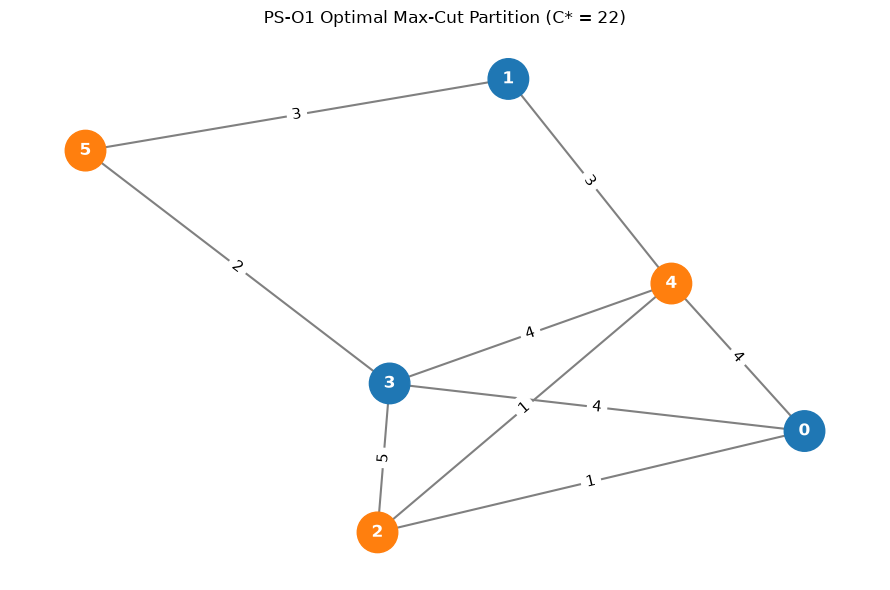

Graph saved successfully!


In [12]:
print("--- 3. Classical Optimum ---")

C_star, optimal_set, random_r, random_p_opt = solve_classical_maxcut()

print(f"C* = {C_star}")
print(f"Optimal Set: {optimal_set}")
print(f"Random Baseline -> r: {random_r:.4f}, P_opt: {random_p_opt:.4f}")
sample_sol = next(iter(optimal_set))
G = nx.Graph()
for u, v, w in EDGES:
    G.add_edge(u, v, weight=w)

# Select one optimal solution for visualization
# Regenerate the optimal Max-Cut partition graph

plt.close("all")

colors = [
    "#1f77b4" if sample_sol[i] == 1 else "#ff7f0e"
    for i in G.nodes()
]

pos = nx.spring_layout(G, seed=42)

fig, ax = plt.subplots(figsize=(9, 6))

nx.draw_networkx(
    G,
    pos,
    ax=ax,
    with_labels=True,
    node_color=colors,
    node_size=850,
    font_color="white",
    font_weight="bold",
    edge_color="gray",
    width=1.5
)

edge_labels = nx.get_edge_attributes(G, "weight")
nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels=edge_labels,
    ax=ax,
    font_size=11
)

ax.set_title(f"PS-O1 Optimal Max-Cut Partition (C* = {C_star})")
ax.axis("off")

fig.tight_layout()
fig.savefig(
    "results/figures/optimal_partition.png",
    dpi=200,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
print("Graph saved successfully!")

## 4. QAOA Parameter Optimization

Optimize the QAOA angles gamma and beta using COBYLA from five random initializations. Select the parameters that produce the highest expected cut value.

In [13]:
print("--- 4. QAOA Parameter Optimization ---")

sim_ideal = AerSimulator(seed_simulator=SEED)

def cost_fn(angles):
    g, b = angles

    qc = build_qaoa_circuit(
        gamma=g,
        beta=b,
        measure=True
    )

    cnts = sim_ideal.run(
        qc,
        shots=SHOTS
    ).result().get_counts()

    mean_val = sum(
        cut_weight(counts_to_x(k)) * v
        for k, v in cnts.items()
    ) / SHOTS

    return -mean_val


runs = []

for seed in [0, 1, 2, 3, 4]:
    rng = np.random.default_rng(seed)
    guess = rng.uniform(0, np.pi, size=2)

    res = minimize(
        cost_fn,
        guess,
        method="COBYLA",
        options={"maxiter": 60}
    )

    runs.append((res.x[0], res.x[1], -res.fun))

    print(
        f"Seed {seed}: gamma={res.x[0]:.4f}, "
        f"beta={res.x[1]:.4f}, "
        f"exp_cut={-res.fun:.4f}"
    )


best_gamma, best_beta, best_score = max(
    runs,
    key=lambda x: x[2]
)

print(f"\nSelected Angles: gamma={best_gamma:.4f}, beta={best_beta:.4f}")
print(f"Best Expected Cut: {best_score:.4f}")
print(f"Approximation Ratio: {best_score / C_star:.4f}")

--- 4. QAOA Parameter Optimization ---
Seed 0: gamma=3.2257, beta=2.7821, exp_cut=17.7170
Seed 1: gamma=2.7045, beta=4.2368, exp_cut=15.5750
Seed 2: gamma=0.7541, beta=0.9485, exp_cut=15.2305
Seed 3: gamma=0.0822, beta=1.2088, exp_cut=17.7200
Seed 4: gamma=2.9330, beta=0.5898, exp_cut=15.1287

Selected Angles: gamma=0.0822, beta=1.2088
Best Expected Cut: 17.7200
Approximation Ratio: 0.8055


## 5. Hardware Benchmarks

Compare Processor B and Processor D using circuit metrics and ideal/noisy simulations. Evaluate approximation ratio and the probability of obtaining an optimal Max-Cut solution.

In [14]:
print("--- 5. Hardware Benchmarks ---")

qc_opt = build_qaoa_circuit(
    gamma=best_gamma,
    beta=best_beta,
    measure=True
)

# Calculate circuit metrics for both processors
metrics_B = circuit_metrics(qc_opt, PROCESSOR_B)
metrics_D = circuit_metrics(qc_opt, D)

def evaluate(sim, tqc):
    cnts = sim.run(tqc, shots=SHOTS).result().get_counts()

    tot = 0
    opt_hits = 0

    for k, v in cnts.items():
        x = counts_to_x(k)
        tot += cut_weight(x) * v

        if x in optimal_set:
            opt_hits += v

    approximation_ratio = (tot / SHOTS) / C_star
    p_opt = opt_hits / SHOTS

    return approximation_ratio, p_opt


# Transpile the circuit for each processor
t_B = transpile_for(qc_opt, PROCESSOR_B)
t_D = transpile_for(qc_opt, D)

# Processor B: ideal and noisy
r_B_id, p_B_id = evaluate(simulator(False), t_B)
r_B_ny, p_B_ny = evaluate(simulator(True, PROCESSOR_B), t_B)

# Processor D: ideal and noisy
r_D_id, p_D_id = evaluate(simulator(False), t_D)
r_D_ny, p_D_ny = evaluate(simulator(True, D), t_D)

print("\nProcessor B:")
print(f"  Logical CX gates: {metrics_B['logical_cx']}")
print(f"  Physical CX gates: {metrics_B['cx']}")
print(f"  Circuit depth: {metrics_B['depth']}")
print(f"  Two-qubit depth: {metrics_B['two_q_depth']}")
print(f"  SWAP gates: {metrics_B['swaps']}")
print(f"  CX overhead: {metrics_B['cx_overhead']}")
print(f"  Ideal: r={r_B_id:.4f}, P_opt={p_B_id:.4f}")
print(f"  Noisy: r={r_B_ny:.4f}, P_opt={p_B_ny:.4f}")

print("\nProcessor D:")
print(f"  Logical CX gates: {metrics_D['logical_cx']}")
print(f"  Physical CX gates: {metrics_D['cx']}")
print(f"  Circuit depth: {metrics_D['depth']}")
print(f"  Two-qubit depth: {metrics_D['two_q_depth']}")
print(f"  SWAP gates: {metrics_D['swaps']}")
print(f"  CX overhead: {metrics_D['cx_overhead']}")
print(f"  Ideal: r={r_D_id:.4f}, P_opt={p_D_id:.4f}")
print(f"  Noisy: r={r_D_ny:.4f}, P_opt={p_D_ny:.4f}")

--- 5. Hardware Benchmarks ---

Processor B:
  Logical CX gates: 18
  Physical CX gates: 21
  Circuit depth: 37
  Two-qubit depth: 17
  SWAP gates: 1
  CX overhead: 3
  Ideal: r=0.8045, P_opt=0.1399
  Noisy: r=0.7833, P_opt=0.1257

Processor D:
  Logical CX gates: 18
  Physical CX gates: 18
  Circuit depth: 29
  Two-qubit depth: 14
  SWAP gates: 0
  CX overhead: 0
  Ideal: r=0.8055, P_opt=0.1414
  Noisy: r=0.7850, P_opt=0.1274


## 6. Export Results

Export the circuit metrics and ideal/noisy simulation results for Processors A, B, and D to a CSV file for analysis and reporting.

In [15]:
print("--- 6. Exporting results/tables/results.csv ---")

csv_cols = [
    "problem_id", "processor", "condition", "executable",
    "logical_qubits", "physical_qubits", "logical_cx", "cx",
    "depth", "two_q_depth", "swaps", "cx_overhead", "shots",
    "quality_metric", "quality_value", "p_opt",
    "classical_optimum", "random_baseline"
]

rows = [
    {
        "problem_id": "PS-O1", "processor": "A",
        "condition": "ideal", "executable": "false",
        "logical_qubits": 6, "physical_qubits": 5,
        "classical_optimum": C_star,
        "random_baseline": f"{random_r:.4f}"
    },
    {
        "problem_id": "PS-O1", "processor": "A",
        "condition": "noisy", "executable": "false",
        "logical_qubits": 6, "physical_qubits": 5,
        "classical_optimum": C_star,
        "random_baseline": f"{random_r:.4f}"
    }
]

for processor, metrics, values in [
    ("B", metrics_B, [
        ("ideal", r_B_id, p_B_id),
        ("noisy", r_B_ny, p_B_ny)
    ]),
    ("D", metrics_D, [
        ("ideal", r_D_id, p_D_id),
        ("noisy", r_D_ny, p_D_ny)
    ])
]:
    for condition, ratio, p_opt in values:
        rows.append({
            "problem_id": "PS-O1",
            "processor": processor,
            "condition": condition,
            "executable": "true",
            "logical_qubits": 6,
            "physical_qubits": 9 if processor == "B" else 6,
            "logical_cx": metrics["logical_cx"],
            "cx": metrics["cx"],
            "depth": metrics["depth"],
            "two_q_depth": metrics["two_q_depth"],
            "swaps": metrics["swaps"],
            "cx_overhead": metrics["cx_overhead"],
            "shots": SHOTS,
            "quality_metric": "approx_ratio",
            "quality_value": f"{ratio:.4f}",
            "p_opt": f"{p_opt:.4f}",
            "classical_optimum": C_star,
            "random_baseline": f"{random_r:.4f}"
        })

with open("results/tables/results.csv", "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=csv_cols)
    writer.writeheader()
    writer.writerows(rows)

print("Saved results/tables/results.csv")
print(f"Exported {len(rows)} benchmark rows.")
print("DONE! All notebook sections completed.")

--- 6. Exporting results/tables/results.csv ---
Saved results/tables/results.csv
Exported 6 benchmark rows.
DONE! All notebook sections completed.
